<a href="https://colab.research.google.com/github/arnavsub/Loan_defaulter-/blob/main/Credit_Risk_ETL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sqlite3
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

RAW_PATH = "/content/credit_risk_dataset.csv"
DB_PATH = "/content/credit_risk.db"

**Extract** the data from the CSV File

In [5]:
def extract(path):
  df = pd.read_csv(path)
  print(f'Extracted {len(df):,} rows')
  return df
raw = extract(RAW_PATH)
raw.head()

Extracted 32,581 rows


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



**Transform**

Delete Duplicates
Keep Rows that are not bad
collects the rejected rows



In [6]:
def transform(df):
  df = df.drop_duplicates()
  bad = (df.person_age > 100) | (df.person_emp_length > 60)
  return df[~bad].copy(), df[bad].copy()
clean, rejected = transform(raw)
print(f'Clean : {len(clean):,} | Rejected: {len(rejected)}')

Clean : 32,409 | Rejected: 7


**Load**

Load the datadrame into SQL lite database as table

creates two tables clean and rejected

In [42]:
def load(clean, rejected, db):
  con = sqlite3.connect(db)
  clean.to_sql('clean_loans', con, if_exists='replace', index=False)
  rejected.to_sql('rejected_loans', con, if_exists='replace', index=False)
  con.close()
load(clean, rejected, DB_PATH)
pd.read_sql("SELECT COUNT(*) AS n FROM rejected_loans", sqlite3.connect(DB_PATH))

,n
0,7


Connect to SQL database

Have loan grade, total number of loans, and percentage that has defaulted

In [15]:
con = sqlite3.connect(DB_PATH)
pd.read_sql("""
    SELECT loan_grade, COUNT(*) AS loans,
           ROUND(AVG(loan_status)*100,1) AS default_pct
    FROM clean_loans GROUP BY loan_grade ORDER BY loan_grade
""", con)

,loan_grade,loans,default_pct
0,A,10702,10.0
1,B,10384,16.3
2,C,6436,20.8
3,D,3619,59.0
4,E,963,64.5
5,F,241,70.5
6,G,64,98.4


Same as before but with person_home_ownership


In [18]:
con = sqlite3.connect(DB_PATH)
pd.read_sql("""
    SELECT person_home_ownership, COUNT(*) AS loans,
           ROUND(AVG(loan_status)*100,1) AS default_pct
    FROM clean_loans GROUP BY person_home_ownership ORDER BY person_home_ownership
""", con)

,person_home_ownership,loans,default_pct
0,MORTGAGE,13366,12.6
1,OTHER,106,31.1
2,OWN,2563,7.5
3,RENT,16374,31.6


Same as before but with loan_tent

In [19]:
con = sqlite3.connect(DB_PATH)
pd.read_sql("""
    SELECT loan_intent, COUNT(*) AS loans,
           ROUND(AVG(loan_status)*100,1) AS default_pct
    FROM clean_loans GROUP BY loan_intent ORDER BY loan_intent
""", con)

,loan_intent,loans,default_pct
0,DEBTCONSOLIDATION,5189,28.7
1,EDUCATION,6409,17.3
2,HOMEIMPROVEMENT,3594,26.2
3,MEDICAL,6042,26.8
4,PERSONAL,5496,19.9
5,VENTURE,5679,14.9


Training the random forest

Seperating Numeric and categorical data

Using column transformer one Hot Encoder to transform categorical data

Using Simple imputer as well.

Puts data into RandomForest Classifier

Fitting model

In [35]:
df = pd.read_sql("Select * FROM clean_loans", sqlite3.connect(DB_PATH))
X, y = df.drop(columns=['loan_status']), df['loan_status']
num = X.select_dtypes(include='number').columns
cat = X.select_dtypes(exclude='number').columns

prep = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('num', SimpleImputer(strategy='median'), num),
])

model = Pipeline([
    ('prep', prep),
    ('rf', RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                       class_weight="balanced_subsample",
                       random_state=42, n_jobs=-1)),
])

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
model.fit(x_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')),
                                                 ('num',
                                                  SimpleImputer(strategy='median'),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object'))])),
                ('rf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=12, min_samples_leaf=5,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Found that the model correctly chose the defaulter about 94% of the time but only caught about 73% of the loans that defaulted. Since it is a higher risk to keep people that ddefault I want to lower the threshold since the cost of catching people who defaulted is higher

In [24]:
prob = model.predict_proba(x_test)[:,1]
print("Test AUC: ", roc_auc_score(y_test, prob))
print("Train AUC: ", roc_auc_score(y_train, model.predict_proba(x_train)[:,1]))
print(classification_report(y_test, model.predict(x_test)))

Test AUC:  0.9367299856017522
Train AUC:  1.0
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5060
           1       0.97      0.73      0.83      1422

    accuracy                           0.94      6482
   macro avg       0.95      0.86      0.90      6482
weighted avg       0.94      0.94      0.93      6482



Used help from claud to see how I could print out the specific threshold values I wanted to choose. I saw that 0.35 seemed to be the best. Even though its accuracy went down, we were less likely to choose a loan deafulter which is cost effective. Went up from 73 to 84%

In [47]:
from sklearn.metrics import precision_score, recall_score

rows = []
for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    p = (prob >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": round(precision_score(y_test, p), 3),
                 "recall": round(recall_score(y_test, p), 3),
                 "flagged": int(p.sum())})
pd.DataFrame(rows)

,threshold,precision,recall,flagged
0,0.20,0.371,0.950,3629
1,0.25,0.451,0.908,2853
2,0.30,0.547,0.873,2264
3,0.35,0.630,0.841,1892
4,0.40,0.711,0.805,1605
5,0.45,0.782,0.778,1411
6,0.50,0.843,0.755,1271
7,0.55,0.902,0.742,1166


Used the threshold to calculate a new precision recall curve and got a value that I was happy about which accounted for cost as well.

In [46]:
from sklearn.metrics import confusion_matrix

THRESHOLD = 0.35
preds = (prob >= THRESHOLD).astype(int)
print(classification_report(y_test, preds))
print(confusion_matrix(y_test, preds))

              precision    recall  f1-score   support

           0       0.95      0.86      0.90      5064
           1       0.63      0.84      0.72      1418

    accuracy                           0.86      6482
   macro avg       0.79      0.85      0.81      6482
weighted avg       0.88      0.86      0.86      6482

[[4364  700]
 [ 226 1192]]


Showed me the important variables and predictors

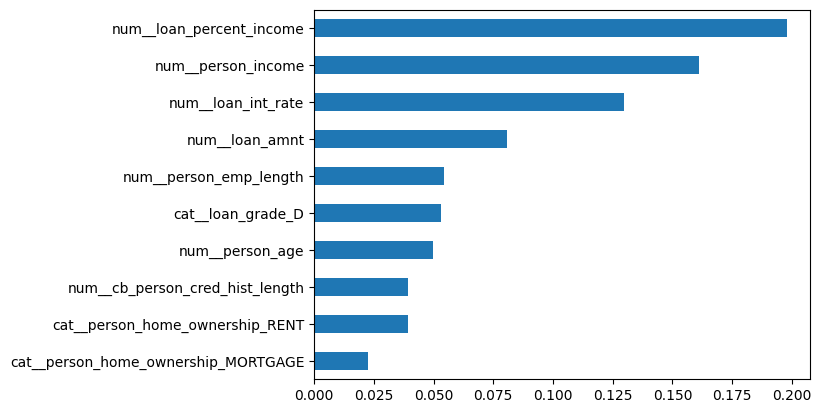

In [25]:
names = model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(model.named_steps["rf"].feature_importances_, index=names)
imp.sort_values().tail(10).plot.barh();